In [3]:

import numpy as np
import matplotlib.pyplot as plt
import os
import torch
import pandas as pd
import adabmDCA as dca
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams.update({'font.size': 14,
                     'text.usetex': True})

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [2]:
import re
import RNA

tokens = dca.get_tokens("rna")

def compute_Tm(sequences, tmin=0, tmax=150, tinc=1):
    T_m_list = []
    for i, seq in enumerate(sequences):
        print(f"Processing temperature {i+1}/{len(sequences)}", end="\r")
        fc = RNA.fold_compound(seq)
        results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
        temperatures = []
        heat_capacities = []
        for result in results:
            # Convert the object to string
            result_str = str(result)
            # Parse the string (assuming format: RNA.RNA.heat_capacity_result(temperature="X", heat_capacity=Y))
            temp_str = float(re.split(r'[ ,"]', str(result))[3])
            hc_str = float(re.split(r'[ ,"]', str(result))[7])

            temperatures.append(temp_str)
            heat_capacities.append(hc_str)

        # Convert to NumPy arrays if needed
        temperatures = np.array(temperatures)
        heat_capacities = np.array(heat_capacities)
        argmax_hc = np.argmax(heat_capacities)
        T_m = temperatures[argmax_hc]
        T_m_list.append(T_m)

    return T_m_list

def compute_heat_capacity_single_seq(sequence, tmin, tmax, tinc=1):
    """
    Compute heat capacity for a given RNA sequence over a temperature range.

    Parameters:
    - sequence: Encoded sequence (list of integers corresponding to tokens).
    - tmin: Starting temperature for heat capacity calculation.
    - tmax: Ending temperature for heat capacity calculation.
    - tinc: Temperature increment (default 1).

    Returns:
    - temperatures: List of temperatures.
    - heat_capacities: List of corresponding heat capacities.
    """
    # Assuming tokens is defined globally (e.g., tokens = get_tokens("rna"))
    string_seq = "".join(tokens[i] for i in sequence)
    fc = RNA.fold_compound(string_seq)
    results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
    temperatures = []
    heat_capacities = []
    for result in results:
        result_str = str(result)
        # Parse temperature and heat capacity from the string
        temp_str = float(re.split(r'[ ,"]', result_str)[3])
        hc_str = float(re.split(r'[ ,"]', result_str)[7])
        temperatures.append(temp_str)
        heat_capacities.append(hc_str)
    return temperatures, heat_capacities


dot_bracket_structure = "(((((((..((((.......)))).(((((.......)))))....(((((.......))))))))))))." # RF00005
RNA.cvar.temperature = 37


def compute_thermoscore(dot_bracket_structure, sequences_ART):
    tokens = dca.get_tokens("rna")
    sequences_RNA = ["".join(tokens[i] for i in sequence) for sequence in sequences_ART]
    thermoscores = []
    for sequence in sequences_RNA:
        fc = RNA.fold_compound(sequence)
        thermoscore = -fc.eval_structure(dot_bracket_structure)
        thermoscores.append(thermoscore)
    return thermoscores

In [8]:
fname_data = "../data/tRNA/RF00005.csv"
fname_model = "../models/tRNA/bmDCA/bmDCA_params.dat"

# Import data
df_data = pd.read_csv(fname_data).dropna().reset_index(drop=True)
# Remove sequences with non-standard characters
df_data = df_data[df_data["sequence"].apply(lambda x: all(c in tokens for c in x))]
data_enc = dca.encode_sequence(df_data["sequence"].tolist(), tokens)
data_oh = torch.tensor(np.eye(len(tokens))[data_enc], device=device, dtype=dtype)
labels_binary = df_data["binary_label"].to_numpy(dtype=np.float32)

### Logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train = data_oh.view(len(data_oh), -1).cpu().numpy()
y_train = labels_binary

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f"Training accuracy: {accuracy:.4f}")

Training accuracy: 0.8018


### Import the bmDCA model

In [10]:
params_DCA = dca.load_params(fname_model, tokens=tokens, device=device, dtype=dtype)

### Wild-type selection

In [11]:
# Fit the PCA on all the data
from sklearn.decomposition import PCA
from adabmDCA.utils import resample_sequences

weights = dca.fasta.compute_weights(data_enc, device=device, dtype=dtype)

seqs_fit_pca = resample_sequences(
    data_oh,
    weights=weights,
    nextract=5 * len(data_oh),
)
seqs_fit_pca = seqs_fit_pca.view(len(seqs_fit_pca), -1).cpu().numpy()
pca = PCA(n_components=2)
pca.fit(seqs_fit_pca)

data_proj = pca.transform(X_train)
labels_data = labels_binary

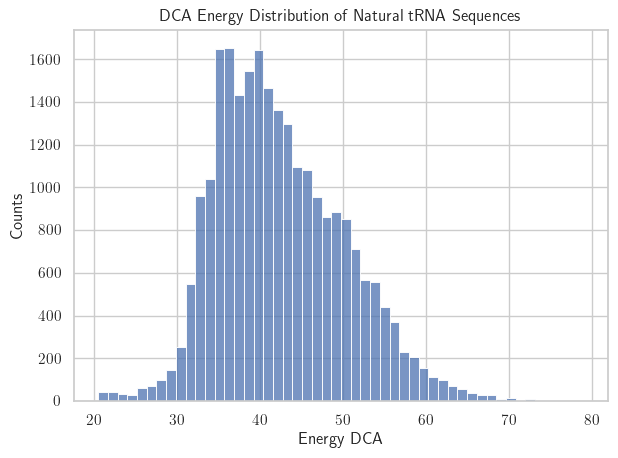

In [13]:
energies_natural = dca.compute_energy(data_oh, params_DCA).cpu().numpy()

sns.histplot(energies_natural, bins=50)
plt.xlabel("Energy DCA")
plt.ylabel("Counts")
plt.title("DCA Energy Distribution of Natural tRNA Sequences")
plt.tight_layout()

In [14]:
mask_wt1 = labels_binary == 0  # keep only sequences with low melting temperature
mask_wt2 = energies_natural < 50  # keep only sequences with low DCA energy
# only wild types without gaps
gap_idx = tokens.index('-')
mask_gap = ~torch.any(data_oh.argmax(2) == gap_idx, dim=1).cpu().numpy()
mask_wt = mask_wt1 & mask_wt2 & mask_gap

wt_idx = 2  # Index of the wild-type sequence
wt = data_oh[mask_wt][wt_idx]
wt_proj = pca.transform(wt.view(1, -1).cpu().numpy())
wt_label = labels_data[mask_wt][wt_idx]
energy_wt = dca.compute_energy(wt.unsqueeze(0), params_DCA).item()
prob_lr_wt = model.predict_proba(wt.view(1, -1).cpu().numpy())[:, 1][0]
print(f"Wild-type label: {wt_label}")
print(f"Wild-type energy: {energy_wt}")
print(f"Wild-type LR probability: {prob_lr_wt:.4f}")

Wild-type label: 0.0
Wild-type energy: 45.13346862792969
Wild-type LR probability: 0.0592


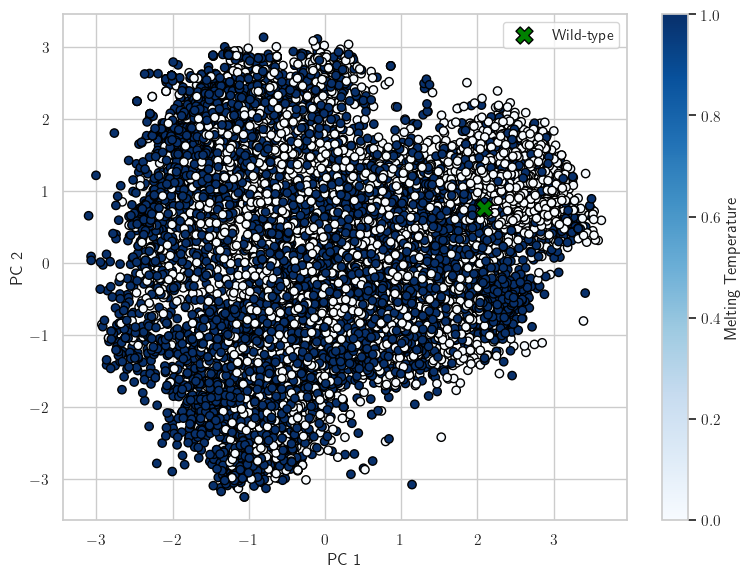

In [18]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(data_proj[:, 0], data_proj[:, 1], c=labels_data, cmap='Blues', alpha=1.0, edgecolors="black")
plt.scatter(wt_proj[0, 0], wt_proj[0, 1], color='green', s=150, edgecolor='black', label='Wild-type', marker='X')
plt.legend()
plt.colorbar(scatter, label='Melting Temperature')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.tight_layout()

In [19]:
print(
    dca.decode_sequence(wt.unsqueeze(0).cpu().numpy(), tokens)[0]
)

UGAGAUGUGGCUCAGUGGUAUAGCAUUUGUCUGGCAUGCAUGAAGCCUAAGUUUGAUCCCUAGCACUGCAA


### Mutate the wild type to improve thermostability

In [20]:
def plot_summary(
    samples_pca: np.ndarray,
    wild_type_pca: np.ndarray,
    data_pca: np.ndarray,
    data_labels: np.ndarray,
    distances: np.ndarray,
    energies: np.ndarray,
    sample_labels: np.ndarray,
    energy_wt: float,
    label_wt: float,
    title: str,
):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5), dpi=100)
    ax = ax.flatten()

    idx = np.argsort(distances)[::-1]

    # Scatter plot PCA
    ax[0].scatter(data_pca[:, 0], data_pca[:, 1], label='Data', alpha=0.5, c=data_labels, cmap='Accent')
    sc = ax[0].scatter(samples_pca[idx, 0], samples_pca[idx, 1], c=distances[idx], cmap='tab20b', label='Samples', edgecolor='black', lw=0.5, s=30)
    ax[0].scatter(wild_type_pca[:, 0], wild_type_pca[:, 1], marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[0].legend()
    ax[0].set_xlabel("PCA 1")
    ax[0].set_ylabel("PCA 2")
    cbar = plt.colorbar(sc, ax=ax[0])
    cbar.set_label(r"Distance from Wild Type")
    
    # Histogram of distances
    ud, uc = np.unique(distances, return_counts=True)
    ax[1].bar(ud, uc, width=0.8, color='skyblue', alpha=0.7, edgecolor='black')
    ax[1].set_xlabel("Hamming Distance from Wild Type")
    
    # Scatter plot of Energy vs Probability
    ax[2].scatter(sample_labels[idx], energies[idx] - energy_wt, c=distances[idx], cmap="tab20b", label=f"Samples")
    ax[2].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
    ax[2].set_xlabel(r"Prob. of high Melting Temperature (LogReg)")
    ax[2].set_title(f"Phase space")
    ax[2].scatter(label_wt, 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[2].set_xlim(0, 1)
    ax[2].legend()
    
    cbar = plt.colorbar(sc, ax=ax[2])
    cbar.set_label(r"Distance from WT")


    fig.suptitle(title, fontsize=16)
    fig.tight_layout()

In [36]:
target_label = 1  # Target melting temperature
gen_strength = 1  # Generation strength
wt_strength = 3.0  # Strength of the wild-type bias
label_strength = 3.0  # Strength of the label bias
num_steps = 1000  # Number of Gibbs steps
num_samples = 50000

def bias_model(
    params_dca,
    logreg_model,
    wt,
    gen_strength=1.0,
    label_strength=1.0,
    wt_strength=1.0,
):
    params_mod = {k: v.clone() for k, v in params_dca.items()}
    params_mod["bias"] *= gen_strength
    params_mod["coupling_matrix"] *= gen_strength
    # Add bias towards the wild-type sequence
    params_mod["bias"] += wt_strength * wt
    # Add bias towards the target label
    logreg_weights = torch.tensor(logreg_model.coef_, device=device, dtype=dtype).view(wt.shape)
    params_mod["bias"] += label_strength * logreg_weights
    # Modify the bias to avoid sampling the gap character
    params_mod["bias"][:, 0] = -9999.0  # Strongly penalize gaps
    return params_mod


params_dca_mod = bias_model(
    params_DCA,
    model,
    wt,
    gen_strength=gen_strength,
    label_strength=label_strength,
    wt_strength=wt_strength,
)
chains_init = wt.repeat(num_samples, 1, 1)

In [37]:
samples = dca.gibbs_sampling(
    chains=chains_init,
    params=params_dca_mod,
    nsweeps=num_steps,
)

# count the number of generated sequences that have gaps
num_gaps = torch.any(samples.argmax(2) == gap_idx, dim=1).sum().item()
print(f"Number of generated sequences with gaps: {num_gaps}/{num_samples} ({num_gaps/num_samples*100:.2f}%)")

Number of generated sequences with gaps: 0/50000 (0.00%)


In [38]:
distances = (wt.shape[0] - dca.get_seqid(chains_init, samples)).cpu().numpy()
energies = dca.compute_energy(samples, params_DCA).cpu().numpy()
labels_pred = model.predict_proba(samples.view(len(samples), -1).cpu().numpy())[:, 1]
labels_pred_wt = model.predict_proba(wt.view(1, -1).cpu().numpy())[:, 1]
energy_wt = dca.compute_energy(wt.unsqueeze(0), params_DCA).item()

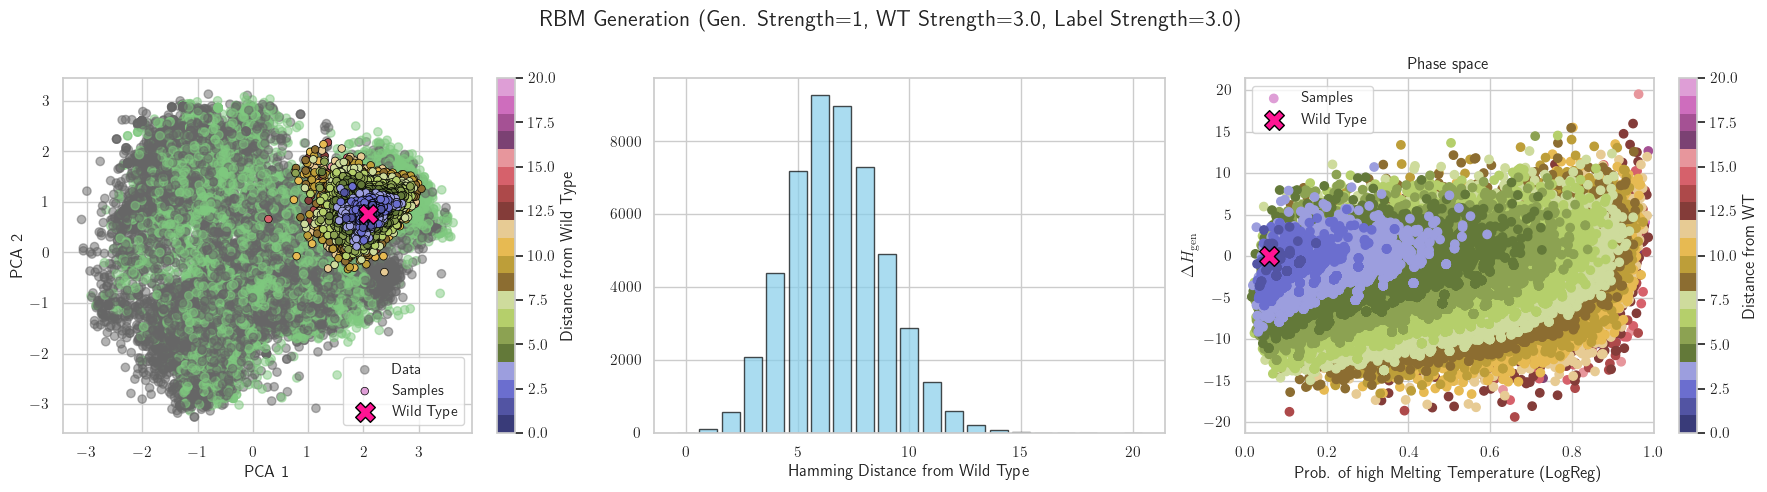

In [39]:
plot_summary(
    samples_pca=pca.transform(samples.view(len(samples), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances,
    energies=energies,
    sample_labels=labels_pred,
    energy_wt=energy_wt,
    label_wt=labels_pred_wt,
    title=f"RBM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})"
)

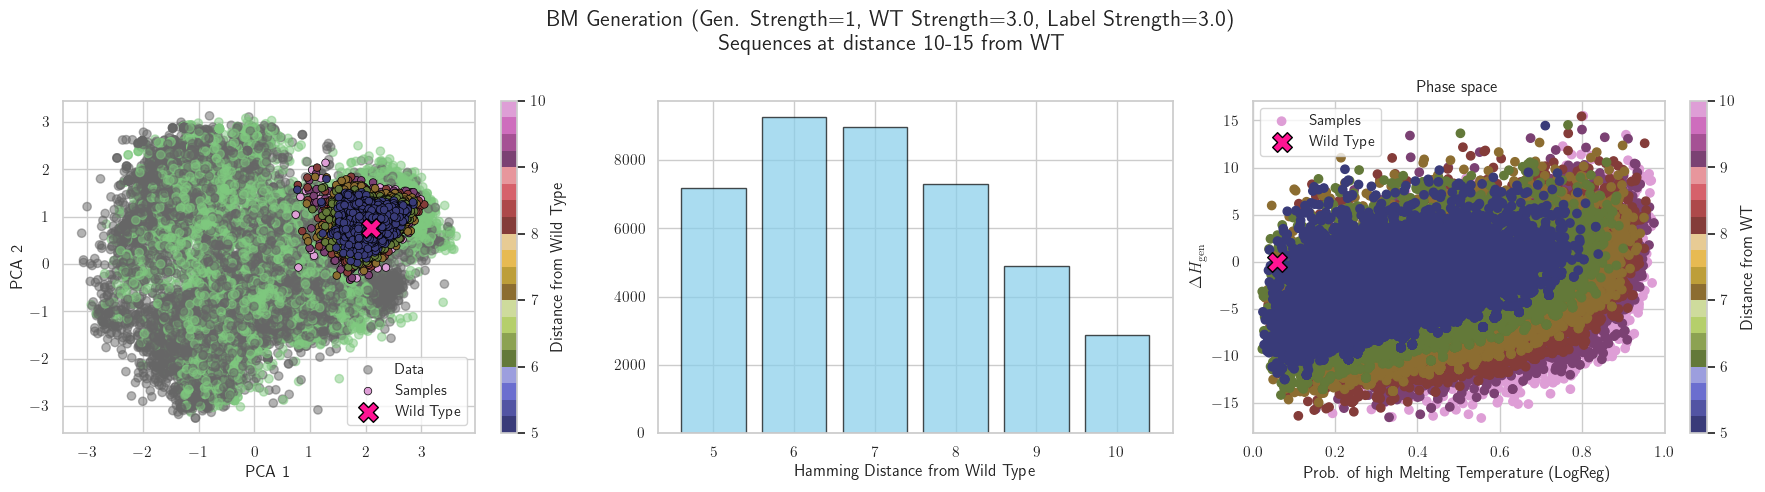

In [41]:
# Keep only sequences at distance 20 - 25
mask = (distances >= 5) & (distances <= 10)
seqs_d = samples[mask]
labels_pred_d = labels_pred[mask]
energies_d = energies[mask]
distances_d = distances[mask]

plot_summary(
    samples_pca=pca.transform(seqs_d.view(len(seqs_d), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances_d,
    energies=energies_d,
    sample_labels=labels_pred_d,
    energy_wt=energy_wt,
    label_wt=labels_pred_wt,
    title=f"BM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})\nSequences at distance 10-15 from WT"
)

In [66]:
# select 4 groups of sequences:
# - low energy, low probability
# - low energy, high probability
# - high energy, low probability
# - high energy, high probability
energy_lb = -5
energy_up = 5
prob_lw = 0.2
prob_up = 0.8

mask1 = (energies_d - energy_wt < energy_lb) & (labels_pred_d < prob_lw)
mask2 = (energies_d - energy_wt < energy_lb) & (labels_pred_d >= prob_up)
mask3 = (energies_d - energy_wt >= energy_up) & (labels_pred_d < prob_lw)
mask4 = (energies_d - energy_wt >= energy_up) & (labels_pred_d >= prob_up)
num_test_max = 100

## Test the generated sequences with the Vienna package

In [67]:
import re
import RNA

def compute_Tm(sequences, tmin=0, tmax=150, tinc=1):
    T_m_list = []
    string_sequences = ["".join(tokens[i] for i in sequence) for sequence in sequences]
    for i, seq in enumerate(string_sequences):
        print(f"Computing Tm for sequence {i+1} of {len(string_sequences)}")
        fc = RNA.fold_compound(seq)
        results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
        temperatures = []
        heat_capacities = []
        for result in results:
            # Convert the object to string
            result_str = str(result)
            # Parse the string (assuming format: RNA.RNA.heat_capacity_result(temperature="X", heat_capacity=Y))
            temp_str = float(re.split(r'[ ,"]', str(result))[3])
            hc_str = float(re.split(r'[ ,"]', str(result))[7])

            temperatures.append(temp_str)
            heat_capacities.append(hc_str)

        # Convert to NumPy arrays if needed
        temperatures = np.array(temperatures)
        heat_capacities = np.array(heat_capacities)
        argmax_hc = np.argmax(heat_capacities)
        T_m = temperatures[argmax_hc]
        T_m_list.append(T_m)

    return T_m_list

In [68]:
import re
import numpy as np
import RNA
from multiprocessing import Pool

def _tm_from_sequence(args):
    import numpy as np, RNA
    import re  # not used if attributes work, kept if fallback is needed
    seq, tmin, tmax, tinc = args
    fc = RNA.fold_compound(seq)
    results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)

    temps = []
    caps = []
    for r in results:
        # Preferred: attribute access
        if hasattr(r, "temperature") and hasattr(r, "heat_capacity"):
            temps.append(float(r.temperature))
            caps.append(float(r.heat_capacity))
        else:
            # Robust regex fallback
            m = re.search(r'temperature\s*=\s*([0-9.+-eE]+).*?heat_capacity\s*=\s*([0-9.+-eE]+)', str(r))
            if not m:
                raise ValueError(f"Unexpected heat_capacity_result format: {str(r)}")
            temps.append(float(m.group(1)))
            caps.append(float(m.group(2)))

    temps = np.asarray(temps)
    caps = np.asarray(caps)
    return float(temps[np.argmax(caps)])


def compute_Tm(sequences, tmin=0, tmax=150, tinc=1, processes=None, chunksize=1):
    string_sequences = ["".join(tokens[i] for i in sequence) for sequence in sequences]
    args_iter = [(seq, tmin, tmax, tinc) for seq in string_sequences]
    with Pool(processes=processes) as pool:
        return pool.map(_tm_from_sequence, args_iter, chunksize=chunksize)



In [69]:
df_results = pd.DataFrame()

for i, mask in enumerate([mask1, mask2, mask3, mask4]):
    num_test = min(num_test_max, mask.sum())
    print(f"Group {i+1}: Number of sequences to test: {num_test}")
    if num_test == 0:
        raise ValueError(f"No sequences found for group {i+1} with the given criteria.")
    prob_group = labels_pred_d[mask][:num_test]
    distances_group = distances_d[mask][:num_test]
    samples_group = seqs_d[mask][:num_test]
    energies_group = energies_d[mask][:num_test]

    # sort data by increasing distance from wt
    distances_sorted_indices = np.argsort(distances_group)
    prob_group = prob_group[distances_sorted_indices]
    distances_group = distances_group[distances_sorted_indices]
    samples_group = samples_group[distances_sorted_indices]
    energies_group = energies_group[distances_sorted_indices]
    
    test_sequences = samples_group.argmax(dim=-1).cpu().numpy()
    Tm_group = compute_Tm(test_sequences, tmin=0, tmax=150, tinc=1, processes=10, chunksize=20)
    thermoscores_group = compute_thermoscore(dot_bracket_structure, test_sequences)
    thermoscores_group = np.array(thermoscores_group)
    df_temp = pd.DataFrame({
        "Group": [f"Group {i+1}"] * num_test,
        "Tm (ViennaRNA)": Tm_group,
        "Thermoscore (ViennaRNA)": thermoscores_group,
        "Predicted Probability (LR)": prob_group,
        "Distance": distances_group,
        "Energy": energies_group,
    })
    df_results = pd.concat([df_results, df_temp], ignore_index=True)

Group 1: Number of sequences to test: 100
Group 2: Number of sequences to test: 100
Group 3: Number of sequences to test: 37
Group 4: Number of sequences to test: 100


In [70]:
Tm_wt = compute_Tm(wt.argmax(dim=-1).cpu().numpy().reshape(1, -1), tmin=0, tmax=150, tinc=1)[0]
thermoscore_wt = compute_thermoscore(dot_bracket_structure, [wt.argmax(dim=-1).cpu().numpy()])[0]
print(f"Wild-type Tm: {Tm_wt}")
print(f"Wild-type Thermoscore: {thermoscore_wt}")

Wild-type Tm: 86.0
Wild-type Thermoscore: 1.7999999523162842


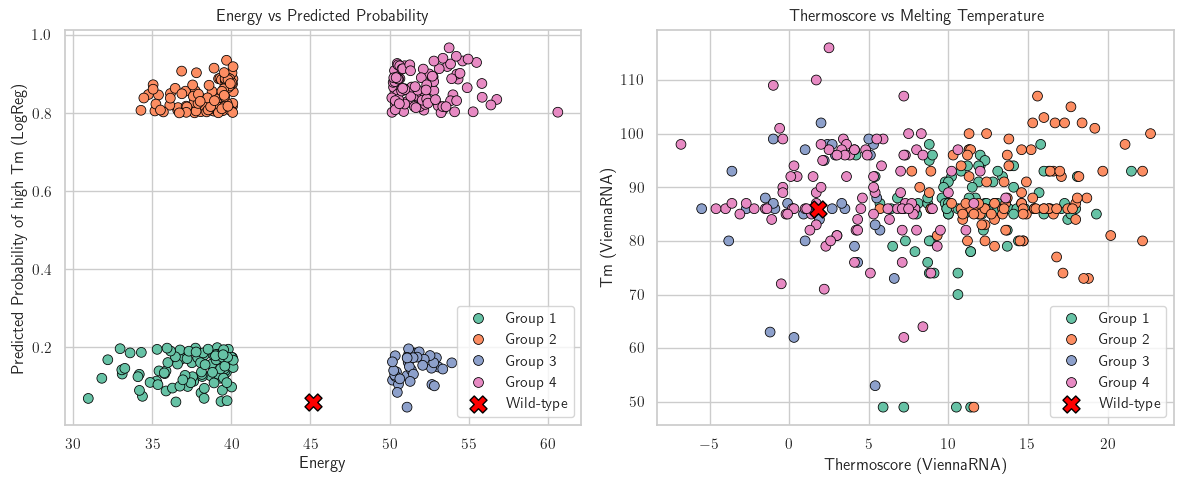

In [71]:
# figure with 2 axes: energy vs probability, thermoscore vs Tm
import seaborn as sns
sns.set(style="whitegrid")

fig, ax = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
ax = ax.flatten()

sns.scatterplot(
    data=df_results,
    x="Energy",
    y="Predicted Probability (LR)",
    hue="Group",
    palette="Set2",
    alpha=1.0,
    edgecolor='black',
    s=50,
    ax=ax[0]
)
ax[0].scatter(energy_wt, labels_pred_wt, color='red', s=150, edgecolor='black', label='Wild-type', marker='X')
ax[0].set_ylabel("Predicted Probability of high Tm (LogReg)")
ax[0].legend()
ax[0].set_title("Energy vs Predicted Probability")

sns.scatterplot(
    data=df_results,
    y="Tm (ViennaRNA)",
    x="Thermoscore (ViennaRNA)",
    hue="Group",
    palette="Set2",
    alpha=1.0,
    edgecolor='black',
    s=50,
    ax=ax[1]
)
ax[1].scatter(thermoscore_wt, Tm_wt, color='red', s=150, edgecolor='black', label='Wild-type', marker='X')
ax[1].set_xlabel("Thermoscore (ViennaRNA)")
ax[1].legend()
ax[1].set_title("Thermoscore vs Melting Temperature")

plt.tight_layout()

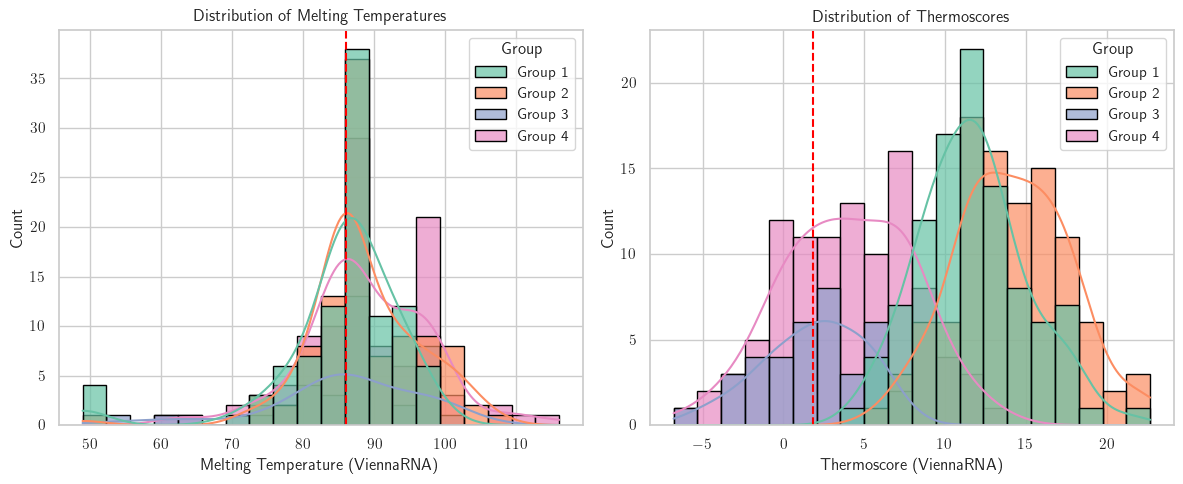

In [72]:
# Show histograms of Tm and Thermoscore for the 4 groups
fig, ax = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
ax = ax.flatten()
sns.histplot(
    data=df_results,
    x="Tm (ViennaRNA)",
    hue="Group",
    palette="Set2",
    alpha=0.7,
    edgecolor='black',
    bins=20,
    ax=ax[0],
    kde=True,
)
ax[0].axvline(Tm_wt, color='red', linestyle='--', label='Wild-type')
ax[0].set_xlabel("Melting Temperature (ViennaRNA)")
ax[0].set_title("Distribution of Melting Temperatures")
sns.histplot(
    data=df_results,
    x="Thermoscore (ViennaRNA)",
    hue="Group",
    palette="Set2",
    alpha=0.7,
    edgecolor='black',
    bins=20,
    ax=ax[1],
    kde=True,
)
ax[1].axvline(thermoscore_wt, color='red', linestyle='--', label='Wild-type')
ax[1].set_xlabel("Thermoscore (ViennaRNA)")
ax[1].set_title("Distribution of Thermoscores")
plt.tight_layout()